## Imports

In [1]:
import numpy as np
from tvb.simulator.lab import *
from jr_models import habJansenRit
import pyvista as pv
import matplotlib.pyplot as plt 
from scipy.spatial import cKDTree
import mindmap as mm

## Data

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- fwd500
Missing objects:
Number of edges:  1089.0


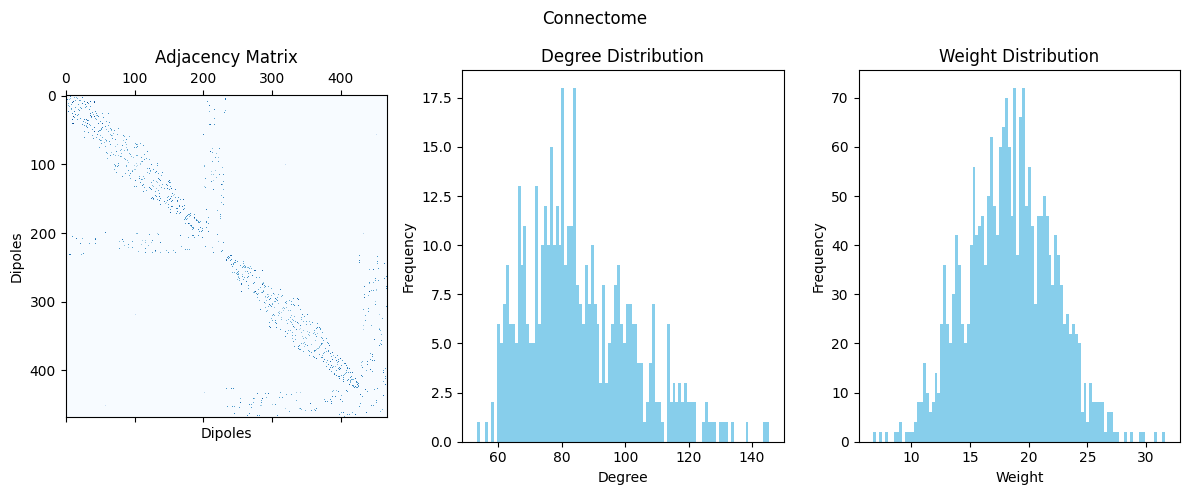

In [2]:
############## Parameters ################
subject = 1
reader  = mm.io.dataset_reader(config = "../../../papers/simf/configuration.yml")
##########################################

data = reader(subject, "fwd500", "eeg")

geometry = mm.utils.build_geometry(data["fwd500"]["src"], dmax=100, k=5, inter_hemi_dmax=10)
data["length500"] = geometry
data["weight500"] = (geometry>0).astype(float)

print("Number of edges: ", np.sum(geometry>0)/2)
mm.viz.plot_connectome(geometry, nonzero=True)

In [3]:
def plot_graph(points, adjacency):
    """
    Parameters
    ----------
    points: np.array (N,3) 
    lines: np.array (N,2)
    """

    P = pv.PolyData(points)
    A1 = adjacency > 0
    A2 = adjacency < 0

    lines1 = []
    lines2 = []
    for i in range(len(A1)):
        for j in range(i, len(A1)):
            if A1[i,j]:
                lines1 += [points[i], points[j]]
            if A2[i,j]:
                lines2 += [points[i], points[j]]
    lines1 = np.array(lines1)
    lines2 = np.array(lines2)

    p = pv.Plotter()
    p.add_mesh(P)
    if len(lines1) > 0:
        p.add_lines(lines1, color="green", width=0.05)
    if len(lines2) > 0:
        p.add_lines(lines2, color="red", width=0.01)

    return p

points = mm.utils.get_src_position(data["fwd500"]["src"])
plot_graph(points, geometry).show()

Widget(value='<iframe src="http://localhost:41673/index.html?ui=P_0x7330980ab410_0&reconnect=auto" class="pyvi…

## Utilities

In [4]:
def build_connectivity(centres, weights, lengths, speed = 3, labels=None):
    """
    Build a TVB connectivity object. 
    """
    if labels is None:
        labels = np.arange(len(centres))

    assert len(centres) == len(weights) == len(lengths) == len(labels), "All data must have same length"

    # delete self loops
    weights = weights - weights*np.eye(weights.shape[0])
    lengths = lengths - lengths*np.eye(lengths.shape[0])

    conn = connectivity.Connectivity(
        weights       = weights,
        tract_lengths = lengths,
        centres       = centres,
        region_labels = labels,
        speed         = np.array([speed])
    )

    # scale weights
    conn.weights = conn.scaled_weights(mode="tract")

    # configure
    conn.configure()

    return conn

def run_simulation(
        conn: connectivity.Connectivity, 
        dt: float = 0.1, 
        eta: float = 0.01, 
        tau_d: float = 10, 
        mu: float = 0.03, 
        gc_val: float = 10, 
        r_intra: float = 0.56,
        r_inter: float = 0.56,
        stimulations: list = [([0], 0.03, 2000)], 
        integration: str = "det"
    ):
    """
    Run a Jansen Rit model with network habituation. 

    Parameters
    ----------
    conn: tvb.Connectivity
        Connectivity object.

    dt: float
        Time step in [ms].

    eta: float
        Habituation speed [-]. 1 is instant.

    tau_d: float
        Reaction time constant in [ms]. 1 is instant.

    mu: float
        Constant input for every node.

    gc_val: float
        Global connectivity constant.

    stimulations: list[tuple[targs, amp, dur]]
        Stimulation periods:
        - targs: list[int]
            Target nodes.
        - stim: float
            Stimulation amplitude in [mV].
        - dur: int
            Stimulation duration in [ms].
    
    integration: str
        Integration mechanism ('det': deterministic or 'stoch': stochastic)

    Returns
    -------
    PSP: np.ndarray(N,T)
        Pyramidal input potentials for every node (N,) over the total simulation duration (T,).

    C: np.ndarray(N,T)
        Habituation state.

    y0: np.ndarray(N, T)
        Pyramidal output potentials.
    """
    N = conn.number_of_regions

    # Neural mass model
    model = habJansenRit(
        v0    = np.array([5.52]),
        eta   = np.array([eta]),
        tau_d = np.array([tau_d]),
        mu    = np.array([mu]),
        r     = np.array([r_intra]),
    )

    # Simulator
    if integration == "det":
        your_integrator = integrators.HeunDeterministic(dt=dt)

    if integration == "stoch":
        sigma           = np.zeros(9)  # 9 state variables
        sigma[3]        = 0.00000025   # noise in excitatory potentials
        your_integrator = integrators.HeunStochastic(dt=dt, noise=noise.Additive(nsig=sigma))

    sim = simulator.Simulator(
        connectivity      = conn,
        model             = model,
        coupling          = coupling.SigmoidalJansenRit(a=np.array([gc_val]), r=np.array([r_inter])),
        integrator        = your_integrator,
        monitors          = [monitors.SubSample(period=1)],
        simulation_length = 2000,   # default, does not matter
    )

    sim.configure()

    # run simulation
    y0 = np.zeros(shape=(0,N))  # pyramidal output potentials
    y1 = np.zeros(shape=(0,N))  # excitatory output potentials
    y2 = np.zeros(shape=(0,N))  # inhibitory output potentials
    C  = np.zeros(shape=(0,N))  # habituation state

    for stim in stimulations:
        targs, amp, dur = stim
        stim_mu = amp if amp > 0 else mu    # use default constant input if amp == 0
        print("mu = ", stim_mu)

        # update simulation parameters
        sim.simulation_length = dur 
        sim.model.mu          = np.ones(N)*mu   # default constant input for none targets
        sim.model.mu[targs]   = stim_mu

        # run
        output = sim.run()

        # stack results
        ssamp = output[0][1]
        y0    = np.vstack([y0, ssamp[:,0,:,0]])
        y1    = np.vstack([y1, ssamp[:,1,:,0]])
        y2    = np.vstack([y2, ssamp[:,2,:,0]])
        C     = np.vstack([C, ssamp[:,3,:,0]])

    PSP = y1 - y2   # Pyramidal input potentials

    return PSP, C, y0

## Beautifull Simulation

In [14]:
print("Running beautifull simulation ...")

no_stim     = [([0], 0, 2000)]
small_pulse = lambda targs, amp, dur: [([], 0, 1000), (targs, amp, dur), ([], 0, 1000)]

################### Parameters ###################
# unit model
eta     = 0.8
tau_d   = 7
mu      = 0.1
r_intra = 0.56
r_inter = 0.56


# network model
gc_val = 100

# input model
stimulation = small_pulse([200], 0.3, 100) # ([targets], amplitude, duration)

# other
dt = 0.1
integration = "det"
##################################################

# build connectivity
centres = mm.utils.get_src_position(data["fwd500"]["src"])
conn    = build_connectivity(centres, data["weight500"], data["length500"])

# run simulation
PSP, C, y0 = run_simulation(
    conn         = conn,
    dt           = dt, 
    eta          = eta,
    tau_d        = tau_d,
    mu           = mu,
    gc_val       = gc_val,
    r_intra      = r_intra,
    r_inter      = r_inter,
    stimulations = stimulation,
    integration  = integration,
)

Running beautifull simulation ...
mu =  0.1
2025-09-09 10:55:33,354 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  0.3
2025-09-09 10:55:53,154 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  0.1
2025-09-09 10:55:54,939 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


## Beautifull visualization

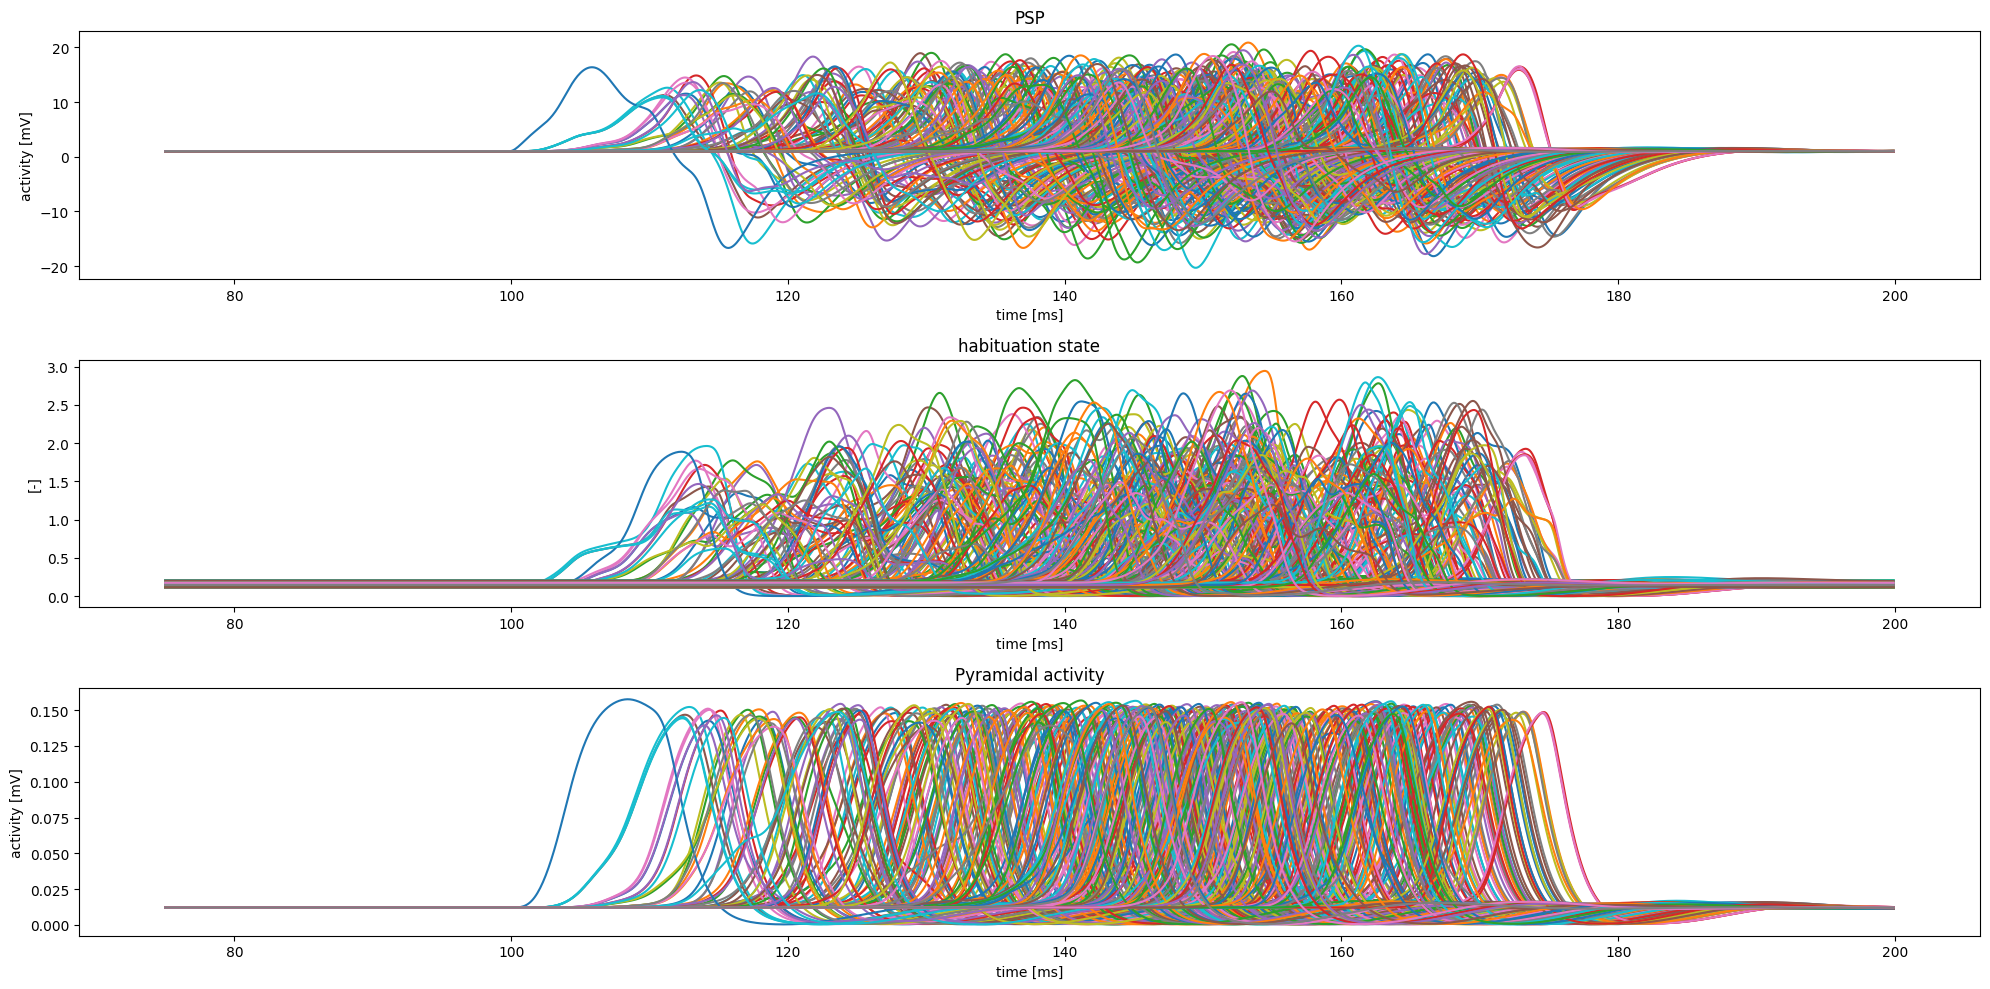

In [16]:
####################### Parameters ####################
start = 75     # start of visualization in [ms]
end   = 200     # end of visualization in [ms]
#######################################################


fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(20,10))

# define first and last index
s_idx = int(start/dt)
e_idx = int(end/dt)

# temporal axis
t     = np.arange(PSP.shape[0])*dt

# plot
axs[0].plot(t[s_idx:e_idx], PSP[s_idx:e_idx,:])
axs[0].set_title("PSP")
axs[0].set_xlabel("time [ms]")
axs[0].set_ylabel("activity [mV]")

axs[1].plot(t[s_idx:e_idx], C[s_idx:e_idx,:])
axs[1].set_title("habituation state")
axs[1].set_xlabel("time [ms]")
axs[1].set_ylabel("[-]")

axs[2].plot(t[s_idx:e_idx], y0[s_idx:e_idx,:])
axs[2].set_title("Pyramidal activity")
axs[2].set_xlabel("time [ms]")
axs[2].set_ylabel("activity [mV]")

plt.tight_layout()
plt.show()

## Beautifull Brain

In [19]:
activity = PSP[s_idx:e_idx,:].T
activity = mm.utils.make_stc(data["fwd500"]["src"], np.abs(activity), t[s_idx], dt)

mm.viz.plot_brain(data["fwd500"]["src"], activity).show()

Widget(value='<iframe src="http://localhost:41673/index.html?ui=P_0x733085925990_2&reconnect=auto" class="pyvi…